In [1]:
import project as p
import numpy as np
import matplotlib.pyplot as plt

p.load_data("data/fits/jw03131-o001_t001_nirspec_g140h-f100lp_s3d.fits")

Set DATE-AVG to '2024-02-19T07:34:54.885' from MJD-AVG.
Set DATE-END to '2024-02-19T08:28:30.725' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to    19.316752 from OBSGEO-[XYZ].
Set OBSGEO-H to 1470239568.529 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


1.0845347442977058 0.00045833083911474954


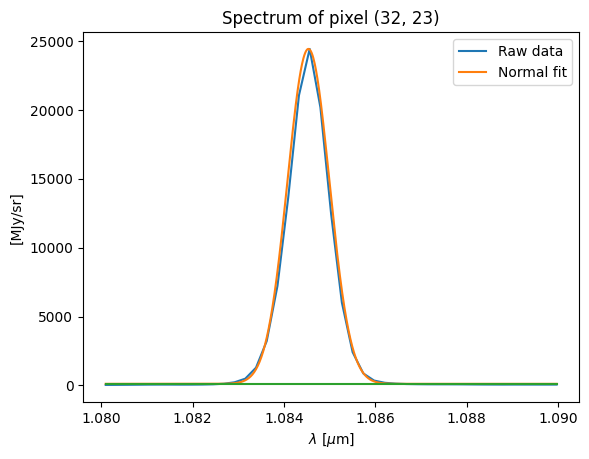

In [2]:

x, y = 32, 23
image = 302

spec_slice = p.spectrum_slice(1.08, 1.09)
spec, background = p.get_spectrum(x, y)

mu, std, a, fn = p.fit_normal(spec, background, spec_slice)

X = p.spectral_axis[spec_slice]
Y = spec[spec_slice]
X_lin = np.linspace(X[0], X[-1], 1000)

print(mu, std)

plt.title(f"Spectrum of pixel ({x}, {y})")
plt.xlabel("$\\lambda$ [$\\mu$m]")
plt.ylabel("[MJy/sr]")
plt.plot(X, Y)
plt.plot(X_lin, fn(X_lin))
plt.plot(X_lin, background.eval(X_lin))
plt.legend(["Raw data", "Normal fit"])
plt.show()